In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, entropy

pd.set_option('display.max_columns', None)
plt.rcParams["figure.figsize"] = (10, 6)
sns.set(style="whitegrid")


In [15]:
df = pd.read_csv("api_data_aadhar_enrolment_500000_1000000.csv") 
df.head()

,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
0,26-10-2025,Andhra Pradesh,Nalgonda,508004,0,1,0
1,26-10-2025,Andhra Pradesh,Nalgonda,508238,1,0,0
2,26-10-2025,Andhra Pradesh,Nalgonda,508278,1,0,0
3,26-10-2025,Andhra Pradesh,Nandyal,518432,0,1,0
4,26-10-2025,Andhra Pradesh,Nandyal,518543,1,0,0


In [17]:
print("Rows, Columns:", df.shape)
df.info()
df.describe(include="all")


Rows, Columns: (500000, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   date            500000 non-null  object
 1   state           500000 non-null  object
 2   district        500000 non-null  object
 3   pincode         500000 non-null  int64 
 4   age_0_5         500000 non-null  int64 
 5   age_5_17        500000 non-null  int64 
 6   age_18_greater  500000 non-null  int64 
dtypes: int64(4), object(3)
memory usage: 26.7+ MB


,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
count,500000,500000,500000,500000.000000,500000.000000,500000.000000,500000.000000
unique,37,52,941,NaN,NaN,NaN,NaN
top,15-12-2025,Uttar Pradesh,Pune,NaN,NaN,NaN,NaN
freq,19426,52416,3343,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,518077.362504,3.009628,1.082962,0.089984
std,NaN,NaN,NaN,204615.861812,4.658289,2.537596,1.073745
min,NaN,NaN,NaN,100000.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,365541.000000,1.000000,0.000000,0.000000
50%,NaN,NaN,NaN,517583.000000,2.000000,0.000000,0.000000
75%,NaN,NaN,NaN,695023.000000,3.000000,1.000000,0.000000


In [6]:
df.describe(include="all")

,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
count,500000,500000,500000,500000.000000,500000.000000,500000.000000,500000.000000
unique,37,52,941,NaN,NaN,NaN,NaN
top,15-12-2025,Uttar Pradesh,Pune,NaN,NaN,NaN,NaN
freq,19426,52416,3343,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,518077.362504,3.009628,1.082962,0.089984
std,NaN,NaN,NaN,204615.861812,4.658289,2.537596,1.073745
min,NaN,NaN,NaN,100000.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,365541.000000,1.000000,0.000000,0.000000
50%,NaN,NaN,NaN,517583.000000,2.000000,0.000000,0.000000
75%,NaN,NaN,NaN,695023.000000,3.000000,1.000000,0.000000


In [18]:
# Drop duplicates
df = df.drop_duplicates()

# Drop rows with missing critical fields
df = df.dropna(subset=["date", "state", "district"])

# Convert date
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")

# Ensure numeric age columns
age_cols = ["age_0_5", "age_5_17", "age_18_greater"]
for col in age_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with zero enrolment
df = df[df[age_cols].sum(axis=1) > 0]

df.head()


,date,state,district,pincode,age_0_5,age_5_17,age_18_greater
0,2025-10-26,Andhra Pradesh,Nalgonda,508004,0,1,0
1,2025-10-26,Andhra Pradesh,Nalgonda,508238,1,0,0
2,2025-10-26,Andhra Pradesh,Nalgonda,508278,1,0,0
3,2025-10-26,Andhra Pradesh,Nandyal,518432,0,1,0
4,2025-10-26,Andhra Pradesh,Nandyal,518543,1,0,0


In [19]:
# Total enrolments
df["total_enrolments"] = (
    df["age_0_5"] + df["age_5_17"] + df["age_18_greater"]
)

# Time features
df["month"] = df["date"].dt.to_period("M")
df["year"] = df["date"].dt.year

df.head()


,date,state,district,pincode,age_0_5,age_5_17,age_18_greater,total_enrolments,month,year
0,2025-10-26,Andhra Pradesh,Nalgonda,508004,0,1,0,1,2025-10,2025
1,2025-10-26,Andhra Pradesh,Nalgonda,508238,1,0,0,1,2025-10,2025
2,2025-10-26,Andhra Pradesh,Nalgonda,508278,1,0,0,1,2025-10,2025
3,2025-10-26,Andhra Pradesh,Nandyal,518432,0,1,0,1,2025-10,2025
4,2025-10-26,Andhra Pradesh,Nandyal,518543,1,0,0,1,2025-10,2025


In [20]:
state_counts = (
    df.groupby("state")["total_enrolments"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

state_counts


state
Uttar Pradesh     327930
Madhya Pradesh    206437
Bihar             202741
West Bengal       147685
Maharashtra       141376
Rajasthan         133773
Tamil Nadu        110725
Karnataka          97333
Gujarat            81718
Jharkhand          69876
Name: total_enrolments, dtype: int64

In [21]:
district_counts = (
    df.groupby("district")["total_enrolments"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

district_counts


district
South 24 Parganas    17031
Murshidabad          15029
Pune                 13929
Thane                13765
North 24 Parganas    12776
Jaipur               11851
Hyderabad            10736
Aurangabad           10577
Bengaluru            10082
East Champaran        9904
Name: total_enrolments, dtype: int64

In [22]:
age_summary = df[age_cols].sum()
age_summary


age_0_5           1454549
age_5_17           522687
age_18_greater      43609
dtype: int64

In [23]:
monthly_trend = (
    df.groupby("month")["total_enrolments"]
    .sum()
    .sort_index()
)

monthly_trend


month
2025-10     271979
2025-11    1052584
2025-12     696282
Freq: M, Name: total_enrolments, dtype: int64

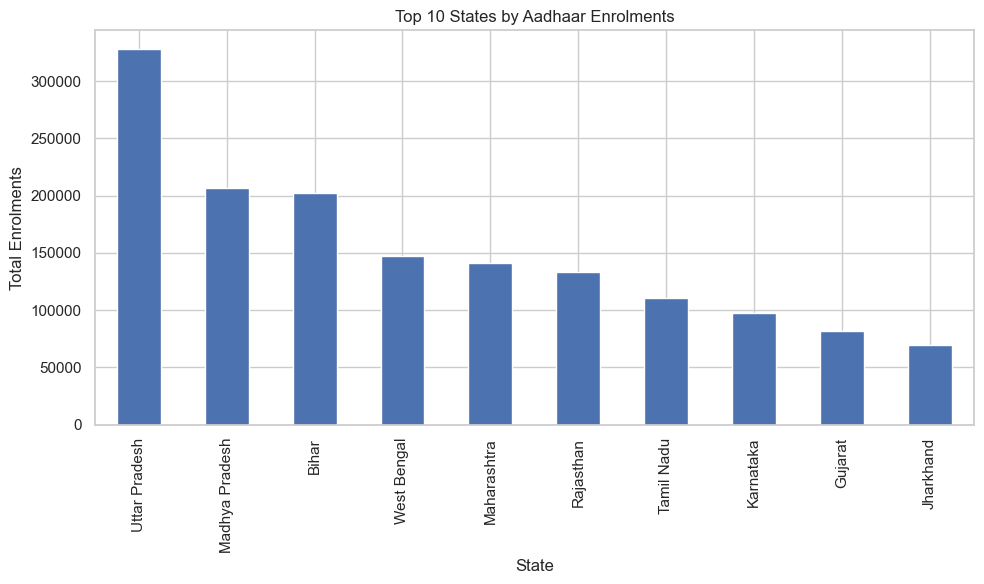

In [24]:
state_counts.plot(kind="bar")
plt.title("Top 10 States by Aadhaar Enrolments")
plt.xlabel("State")
plt.ylabel("Total Enrolments")
plt.tight_layout()
plt.show()


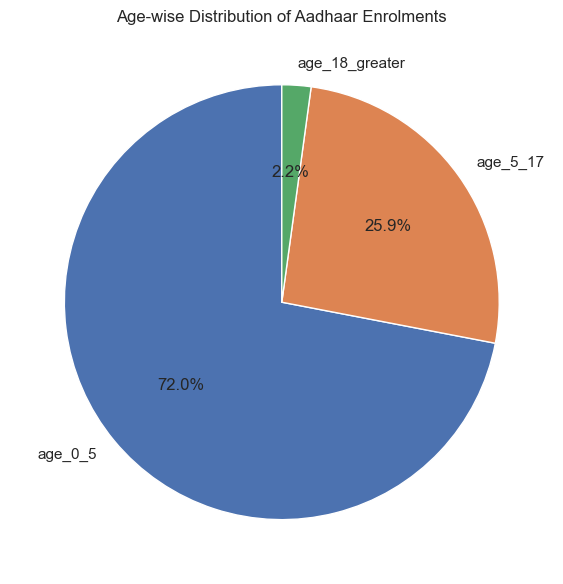

In [25]:
age_summary.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Age-wise Distribution of Aadhaar Enrolments")
plt.ylabel("")
plt.tight_layout()
plt.show()


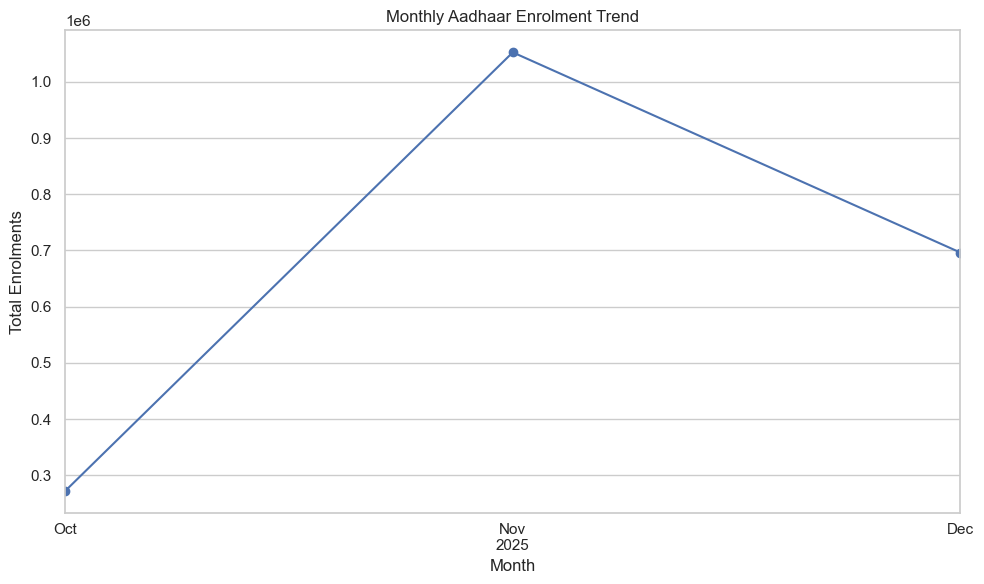

In [26]:
monthly_trend.plot(marker="o")
plt.title("Monthly Aadhaar Enrolment Trend")
plt.xlabel("Month")
plt.ylabel("Total Enrolments")
plt.grid(True)
plt.tight_layout()
plt.show()


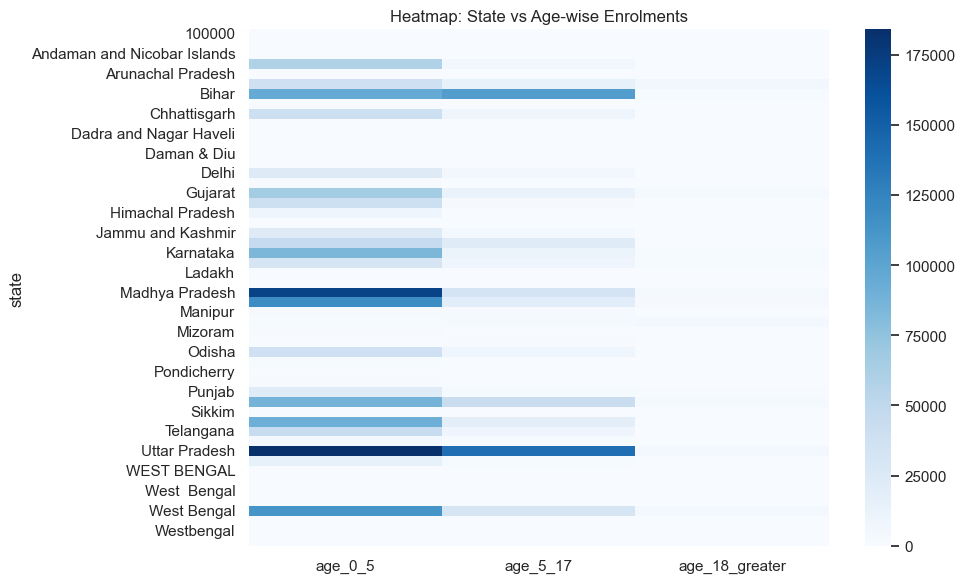

In [27]:
pivot = df.groupby("state")[age_cols].sum()

sns.heatmap(pivot, cmap="Blues")
plt.title("Heatmap: State vs Age-wise Enrolments")
plt.tight_layout()
plt.show()


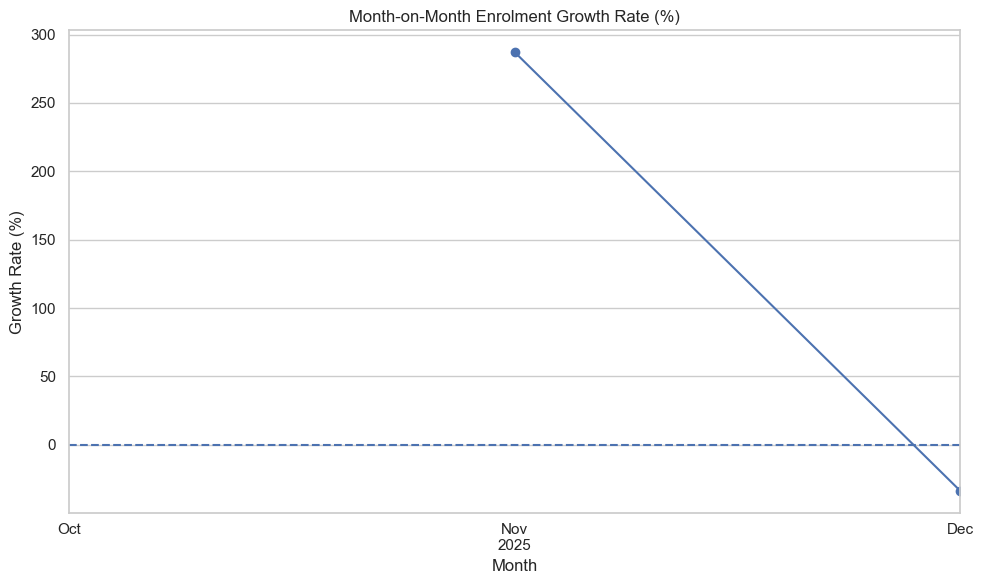

In [28]:
monthly_growth = monthly_trend.pct_change() * 100

monthly_growth.plot(marker="o")
plt.axhline(0, linestyle="--")
plt.title("Month-on-Month Enrolment Growth Rate (%)")
plt.xlabel("Month")
plt.ylabel("Growth Rate (%)")
plt.tight_layout()
plt.show()


In [29]:
district_density = (
    df.groupby("district")["total_enrolments"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

district_density


district
Eastern West Khasi Hills    25.846154
North East Delhi            20.726027
Mewat                       17.543269
Rampur                      17.238971
Morena                      16.955959
100000                      16.750000
West Champaran              15.493103
Jhabua                      15.421818
Sheopur                     14.739394
Barwani                     14.301075
Name: total_enrolments, dtype: float64

In [30]:
national_total = df["total_enrolments"].sum()

state_contribution = (
    df.groupby("state")["total_enrolments"].sum()
    / national_total * 100
).sort_values(ascending=False)

state_contribution.head(10)


state
Uttar Pradesh     16.227370
Madhya Pradesh    10.215380
Bihar             10.032486
West Bengal        7.308082
Maharashtra        6.995885
Rajasthan          6.619657
Tamil Nadu         5.479144
Karnataka          4.816451
Gujarat            4.043754
Jharkhand          3.457761
Name: total_enrolments, dtype: float64

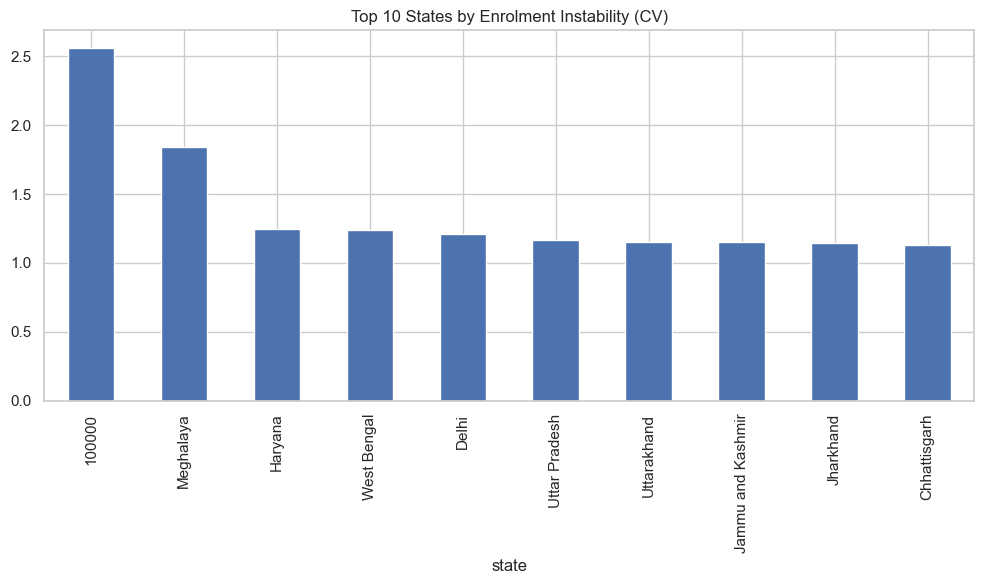

In [31]:
state_cv = df.groupby("state")["total_enrolments"].agg(["mean", "std"])
state_cv["cv"] = state_cv["std"] / (state_cv["mean"] + 1)

top_cv = state_cv["cv"].sort_values(ascending=False).head(10)
top_cv.plot(kind="bar")
plt.title("Top 10 States by Enrolment Instability (CV)")
plt.tight_layout()
plt.show()


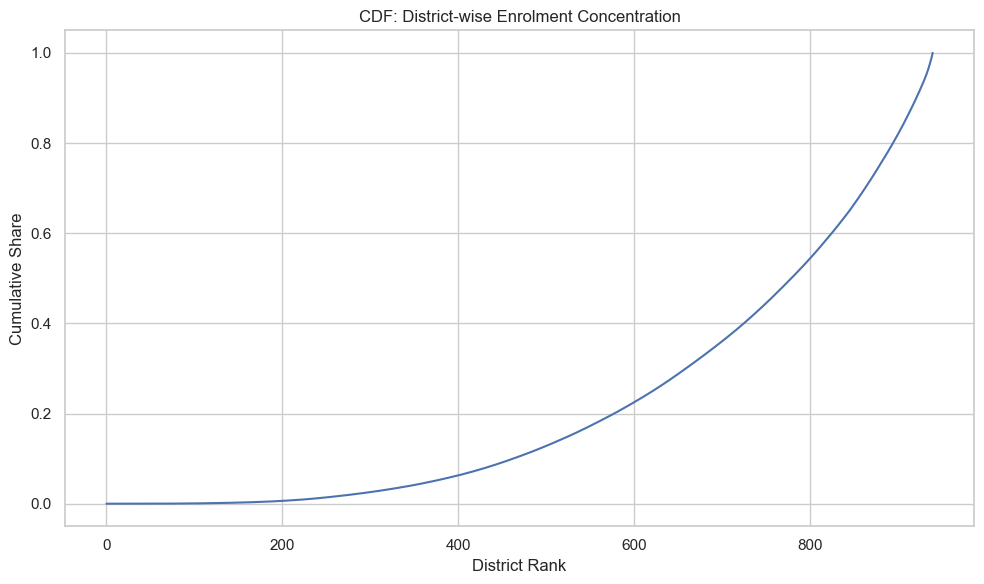

In [32]:
district_totals = (
    df.groupby("district")["total_enrolments"]
    .sum()
    .sort_values()
)

cdf = district_totals.cumsum() / district_totals.sum()

plt.plot(cdf.values)
plt.title("CDF: District-wise Enrolment Concentration")
plt.xlabel("District Rank")
plt.ylabel("Cumulative Share")
plt.tight_layout()
plt.show()


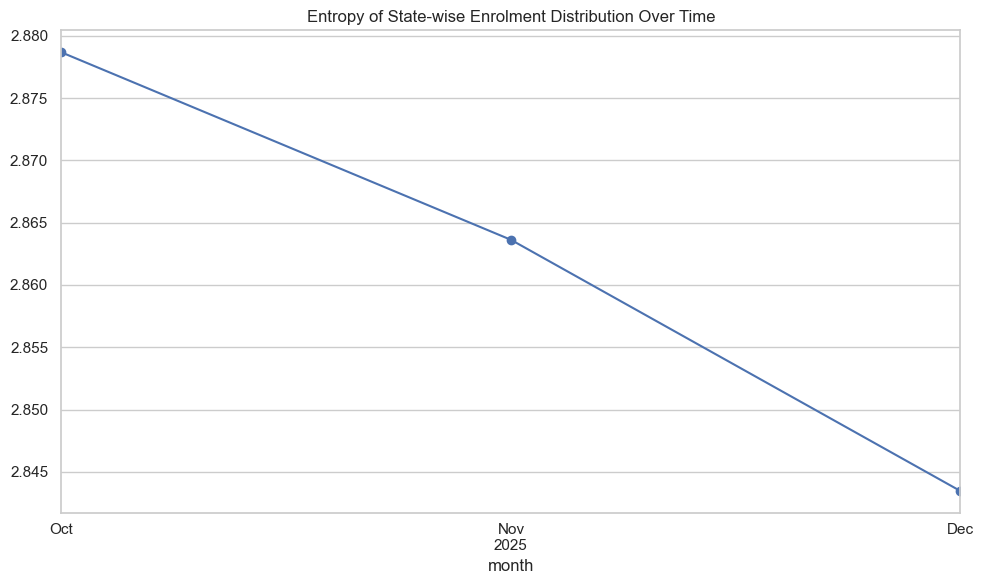

In [33]:
state_month_matrix = (
    df.groupby(["month", "state"])["total_enrolments"]
    .sum()
    .unstack(fill_value=0)
)

diversity = state_month_matrix.apply(lambda x: entropy(x + 1), axis=1)

diversity.plot(marker="o")
plt.title("Entropy of State-wise Enrolment Distribution Over Time")
plt.tight_layout()
plt.show()


In [34]:
print("Final Columns:", df.columns)
print("Total Records:", len(df))
print("National Total Enrolments:", national_total)


Final Columns: Index(['date', 'state', 'district', 'pincode', 'age_0_5', 'age_5_17',
       'age_18_greater', 'total_enrolments', 'month', 'year'],
      dtype='object')
Total Records: 484196
National Total Enrolments: 2020845
